# Seminar 3: Using a real GPT-style Transformer

You have already worked with tokenization, embeddings, positional information, self-attention, masked self-attention, and next-token prediction in simplified examples. Now you will inspect those ideas inside a real pretrained Transformer model.

Your task is to complete **10 missing pieces of code**. At the end, everyone should reach the same final line:

> **CLASS CHECKPOINT: 10/10 PASS**

Read the comments carefully and use the hints.

In [1]:
# Install Hugging Face Transformers if needed
# In Google Colab, PyTorch is normally already available
# %pip install -q transformers

import torch
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

torch.manual_seed(0)
print("PyTorch version:", torch.__version__)

c:\Users\laand\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch version: 2.14.0+cpu


## 1. Load a real decoder-only Transformer

We use **DistilGPT-2**, a smaller GPT-2-family model. It contains real pretrained weights and real Transformer decoder blocks, but is lightweight enough for our today's task.

The model is pretrained: **we are not training it here**. We are only performing **inference**.

In [2]:
MODEL_NAME = "distilgpt2"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

# "eager" attention makes it possible to inspect the attention matrices more easily
try:
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        attn_implementation="eager"
    )
except TypeError:
    # Compatibility fallback for older Transformers versions
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)

model.eval()

print("Model loaded:", MODEL_NAME)
print("Decoder blocks:", model.config.n_layer)
print("Attention heads per block:", model.config.n_head)
print("Hidden size:", model.config.n_embd)

c:\Users\laand\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\laand\.cache\huggingface\hub\models--distilgpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\laand\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.p

Model loaded: distilgpt2
Decoder blocks: 6
Attention heads per block: 12
Hidden size: 768


## 2. Give the model a short prompt

We use a deliberately short and predictable prompt:

> **The capital of France is Paris. The capital of Italy is**

It is:
- short enough to make the attention matrix readable,
- predictable enough that you can make a hypothesis,
- structured enough to show that the model uses context.


In [3]:
prompt = "The capital of France is Paris. The capital of Italy is"

# TODO 1 — TOKENIZE THE TEXT
# Convert the prompt into PyTorch tensors using the tokenizer.
# Hint: call tokenizer(...) and request return_tensors="pt".
inputs = tokenizer(prompt, return_tensors="pt")

# TODO 2 — EXTRACT THE TOKEN IDs
# We want the first (and only) sequence from the batch.
input_ids = inputs["input_ids"][0]

# TODO 3 — CONVERT IDs BACK TO READABLE TOKENS
# This lets us inspect the actual subword tokens used by the model.
tokens = tokenizer.convert_ids_to_tokens(input_ids.tolist())

print("Prompt:", prompt)
print("Number of tokens:", len(tokens))
print("Input tensor shape:", tuple(inputs["input_ids"].shape))

Prompt: The capital of France is Paris. The capital of Italy is
Number of tokens: 12
Input tensor shape: (1, 12)


In [4]:
# Inspect positions, tokens, and token IDs
# Position is explicit here only for display; the model has its own learned positional representations.

token_table = pd.DataFrame({
    "position": list(range(len(tokens))),
    "token": tokens,
    "token_id": input_ids.tolist()
})

token_table

,position,token,token_id
0,0,The,464
1,1,Ġcapital,3139
2,2,Ġof,286
3,3,ĠFrance,4881
4,4,Ġis,318
5,5,ĠParis,6342
6,6,.,13
7,7,ĠThe,383
8,8,Ġcapital,3139
9,9,Ġof,286


## 2b. Inspect real token and positional embeddings

In the earlier toy notebook, embeddings were small hand-written vectors. In this real GPT-style model, each token ID is mapped to a **learned dense vector**.

DistilGPT-2 also has a learned **positional embedding** for each sequence position. These two vectors have the same hidden dimension and are **added together** before the Transformer blocks process them.

In [5]:
with torch.no_grad():
    token_embeddings = model.transformer.wte(inputs["input_ids"]) # wte = word/token embedding table
    positions = torch.arange(inputs["input_ids"].shape[1])
    position_embeddings = model.transformer.wpe(positions) # wpe = the model's learned positional embedding table
    initial_representations = token_embeddings + position_embeddings

print("Token embedding shape:", tuple(token_embeddings.shape))
print("Position embedding shape:", tuple(position_embeddings.shape))
print("Combined representation shape:", tuple(initial_representations.shape))
print("Hidden size:", initial_representations.shape[-1])

Token embedding shape: (1, 12, 768)
Position embedding shape: (12, 768)
Combined representation shape: (1, 12, 768)
Hidden size: 768


**Interpretation:** the token embedding answers roughly **“what token is this?”**, while positional information tells the model **“where is it?”**. Their sum has the same hidden size as either component.

## 3. Run the prompt through the Transformer

This is where the sequence passes through the stack of decoder blocks we discussed earlier.

This one line performs a lot of work:

1. the initial representations enter decoder block 1;
2. masked multi-head self-attention mixes information across allowed token positions;
3. the feed-forward network transforms each position;
4. residual connections and layer normalization support information flow;
5. the process repeats through all 6 decoder blocks;
6. the final hidden representations are converted to vocabulary scores.

The model returns a large set of numbers called **logits**. For a causal language model, each sequence position has one score for every possible vocabulary token.

We also request the **attention matrices** so that we can inspect causal/masked self-attention later.

In [6]:
with torch.no_grad():
    # TODO 4 — RUN THE MODEL
    # Pass the tokenized inputs to the model and request attentions.
    outputs = model(**inputs, output_attentions=True)

print("Model run complete.")

Model run complete.


# 4. Logits: the model scores every possible next token

A causal language model does not immediately output a word. It first produces **logits**.

A logit is an **unnormalized score**. Higher generally means the model considers that vocabulary item more compatible with the prediction at that position.

The output shape is:

**batch × sequence positions × vocabulary size**

In [ ]:
# TODO 5 — EXTRACT THE LOGITS
logits = outputs.logits

print("Logits shape:", tuple(logits.shape))
print("Interpretation: batch x sequence positions x vocabulary size")

Logits shape: (1, 12, 50257)
Interpretation: batch × sequence positions × vocabulary size


### Think before continuing

If the logits have shape:

`1 × sequence_length × vocabulary_size`

then the model has produced a vocabulary-sized prediction at **every token position**. For next-token generation, we need the prediction after the **last prompt token**.

In [8]:
# TODO 6 — SELECT THE LAST POSITION
    # 0  = first/only item in the batch
    # -1 = last token position
    # :  = all vocabulary scores
# Keep all vocabulary scores, but only for the final prompt position.
next_token_logits = logits[0, -1, :]

# TODO 7 — CONVERT LOGITS TO PROBABILITIES
# Softmax should be applied across the vocabulary dimension.
next_token_probs = torch.softmax(next_token_logits, dim=-1)

# TODO 8 — FIND THE MOST PROBABLE NEXT TOKEN ID
next_token_id = torch.argmax(next_token_probs).item()

next_token = tokenizer.decode([next_token_id])

print("Next-token logit vector shape:", tuple(next_token_logits.shape))
print("Predicted next token ID:", next_token_id)
print("Predicted next token:", repr(next_token))
print("Probability sum:", abs(next_token_probs.sum().item() - 1.0) < 1e-4)

Next-token logit vector shape: (50257,)
Predicted next token ID: 10598
Predicted next token: ' Rome'
Probability sum: True


In [9]:
# Show the five highest probability next-token candidates:
top_probs, top_ids = torch.topk(next_token_probs, k=5)

top5 = pd.DataFrame({
    "token": [tokenizer.decode([i.item()]) for i in top_ids],
    "probability": top_probs.tolist()
})

top5

,token,probability
0,Rome,0.208020
1,Paris,0.137538
2,the,0.073763
3,Milan,0.061759
4,Naples,0.023847


## 5. Inspect real masked self-attention

A GPT-style decoder uses **causal/masked self-attention**. During training, the full sequence exists in the dataset, but each position must be prevented from looking at future positions.

The attention output has four dimensions:

**batch × heads × query positions × key positions**

We will inspect the **last decoder block** and average across its attention heads to make the matrix easier to read.

In [10]:
# TODO 9 — GET THE LAST DECODER BLOCK'S ATTENTION
last_layer_attention = outputs.attentions[-1]

print("Last layer attention shape:", tuple(last_layer_attention.shape))

# Average across attention heads: sequence × sequence
mean_attention = last_layer_attention[0].mean(dim=0)

attention_table = pd.DataFrame(
    mean_attention.detach().cpu().numpy(),
    index=tokens,
    columns=tokens
)

attention_table.round(3)

Last layer attention shape: (1, 12, 12, 12)


,The,Ġcapital,Ġof,ĠFrance,Ġis,ĠParis,.,ĠThe,Ġcapital,Ġof,ĠItaly,Ġis
The,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Ġcapital,0.871,0.129,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Ġof,0.777,0.096,0.127,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
ĠFrance,0.755,0.131,0.057,0.057,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Ġis,0.759,0.065,0.039,0.067,0.069,0.000,0.000,0.000,0.000,0.000,0.000,0.000
ĠParis,0.764,0.042,0.032,0.033,0.086,0.043,0.000,0.000,0.000,0.000,0.000,0.000
.,0.576,0.036,0.020,0.070,0.053,0.098,0.146,0.000,0.000,0.000,0.000,0.000
ĠThe,0.597,0.057,0.030,0.064,0.054,0.084,0.065,0.049,0.000,0.000,0.000,0.000
Ġcapital,0.611,0.023,0.027,0.037,0.048,0.033,0.083,0.113,0.025,0.000,0.000,0.000
Ġof,0.579,0.021,0.035,0.100,0.038,0.076,0.068,0.047,0.014,0.021,0.000,0.000


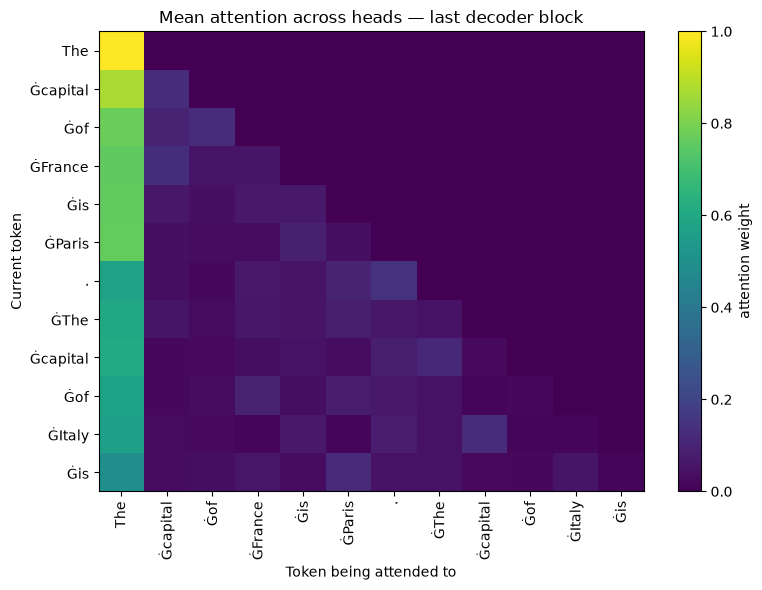

In [11]:
# Visualise the attention matrix.
# Rows = token doing the attending (query position)
# Columns = token being attended to (key position)

plt.figure(figsize=(8, 6))
plt.imshow(mean_attention.detach().cpu().numpy(), aspect="auto")
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("Token being attended to")
plt.ylabel("Current token")
plt.title("Mean attention across heads — last decoder block")
plt.colorbar(label="attention weight")
plt.tight_layout()
plt.show()

In [12]:
# Check whether any attention leaks into future positions.
# The upper triangle (above the diagonal) represents future tokens.
future_attention = torch.triu(mean_attention, diagonal=1)
max_future_attention = future_attention.max().item()

print("Maximum attention weight assigned to a future token:", max_future_attention)

if max_future_attention < 1e-6:
    print("Causal-mask check: PASS")
else:
    print("Causal-mask check: investigate")

Maximum attention weight assigned to a future token: 0.0
Causal-mask check: PASS


### Why this matters

During **generation**, future tokens do not exist yet. During **training**, however, the full training sentence is available. The causal mask prevents the model from "cheating" by looking at tokens it is supposed to predict later.

The mask therefore lets a Transformer process many positions in parallel during training while preserving the rule:

> **each position may use the past and itself, but not the future.**

## 6. Generate more than one token

So far we manually selected one next token from the final probability distribution. Real generation simply repeats the same basic cycle:

**predict next-token distribution → choose one token → append it → run again → choose another → ...**

We will use greedy decoding (`do_sample=False`) so that everyone should obtain the same continuation.

In [13]:
# TODO 10 — GENERATE A SHORT CONTINUATION
# Use the same tokenized prompt, generate 12 new tokens, and do not sample.
generated_ids = model.generate(**inputs, max_new_tokens=12, do_sample=False, pad_token_id=tokenizer.pad_token_id)

generated_text = tokenizer.decode(generated_ids[0], skip_special_tokens=True)

print(generated_text)

The capital of France is Paris. The capital of Italy is Rome.


The French capital is Paris.



## 7. Final class checkpoint

Run this cell only after all 10 TODOs work. It checks the **relationships between your results**, not just whether variables exist.

Everyone who completed the exercise correctly should finish with:

> **CLASS CHECKPOINT: 10/10 PASS**

In [14]:
checks = {
    "TODO 1 — tokenized input": "input_ids" in inputs,
    "TODO 2 — one sequence of IDs": isinstance(input_ids, torch.Tensor) and input_ids.ndim == 1,
    "TODO 3 — tokens match IDs": len(tokens) == len(input_ids),
    "TODO 4 — model produced attentions": outputs.attentions is not None,
    "TODO 5 — logits have sequence length": logits.shape[1] == len(input_ids),
    "TODO 6 — last-position vector has vocab size": next_token_logits.shape[0] == logits.shape[-1],
    "TODO 7 — probabilities approximately sum to 1": abs(next_token_probs.sum().item() - 1.0) < 1e-4,
    "TODO 8 — selected token is argmax": next_token_id == torch.argmax(next_token_probs).item(),
    "TODO 9 — future attention is blocked": max_future_attention < 1e-6,
    "TODO 10 — generation added tokens": generated_ids.shape[1] > inputs["input_ids"].shape[1],
}

for name, passed in checks.items():
    print(("✓" if passed else "✗"), name)

score = sum(checks.values())
print()
print("Model:", MODEL_NAME)
print(
    f"Architecture: layers={model.config.n_layer} | "
    f"heads={model.config.n_head} | hidden={model.config.n_embd}"
)
print(f"Future-attention maximum: {max_future_attention:.2e}")
print()
print(f"CLASS CHECKPOINT: {score}/10 " + ("PASS" if score == 10 else "NOT YET"))

✓ TODO 1 — tokenized input
✓ TODO 2 — one sequence of IDs
✓ TODO 3 — tokens match IDs
✓ TODO 4 — model produced attentions
✓ TODO 5 — logits have sequence length
✓ TODO 6 — last-position vector has vocab size
✓ TODO 7 — probabilities approximately sum to 1
✓ TODO 8 — selected token is argmax
✓ TODO 9 — future attention is blocked
✓ TODO 10 — generation added tokens

Model: distilgpt2
Architecture: layers=6 | heads=12 | hidden=768
Future-attention maximum: 0.00e+00

CLASS CHECKPOINT: 10/10 PASS


## 8. Optional challenge

Change only the country in the prompt and inspect the model's most probable next token.

Try, for example:

- `The capital of France is Paris. The capital of Hungary is`
- `The capital of France is Paris. The capital of Germany is`

Then answer:

1. Which part of the pipeline changes when the text changes?
2. Does the model still use the same vocabulary and model parameters?
3. Why can the next-token distribution change even though the model itself has not been retrained?

In [15]:
# Optional challenge (no missing code):
for country in ["Hungary", "Germany"]:
    test_prompt = f"The capital of France is Paris. The capital of {country} is"
    test_inputs = tokenizer(test_prompt, return_tensors="pt")
    with torch.no_grad():
        test_logits = model(**test_inputs).logits[0, -1, :]
    test_id = torch.argmax(test_logits).item()
    print(country, "->", repr(tokenizer.decode([test_id])))

Hungary -> ' Budapest'
Germany -> ' Paris'


## Final discussion

Try to explain these in your own words:

1. What is the difference between a **token**, a **token ID**, and an **embedding/hidden representation**?
2. Why do the logits have a value for every vocabulary token?
3. Why do we use the **last sequence position** for the next-token prediction?
4. What evidence did you see that the decoder uses **causal/masked self-attention**?
5. Why is generation autoregressive even though Transformer training can process many positions in parallel?